# 05 — Peramalan Harga: naif → ARIMA → SARIMAX

Notebook ini menjawab sub-pertanyaan 4: **apakah anomali cuaca bisa memperbaiki ramalan
harga kopi dibandingkan baseline naif/ARIMA?**

Target: `log(arabica_usd_kg)`. Semua metrik dilaporkan dalam **skala asli (USD/kg)** hasil
back-transform, supaya angkanya bisa dibaca langsung — MAE 0,25 berarti meleset rata-rata
25 sen per kilogram.

Validasi: **walk-forward expanding window**. Model di-fit **ulang di setiap origin**, bukan
sekali lalu meramal semuanya. Tidak ada `train_test_split` acak — mengacak deret waktu akan
membocorkan masa depan ke masa lalu.

## PREDIKSI (ditulis sebelum model dijalankan)

> **Prediksi: baseline naif tidak akan dikalahkan secara berarti, karena event study
> menunjukkan informasi frost terserap dalam ~2 minggu — jauh lebih cepat dari resolusi
> bulanan. Jika SARIMAX justru menang di h=6, itu bertentangan dengan temuan tersebut dan
> wajib dijelaskan.**

Dasarnya notebook 04: CAR melonjak +25,5% dalam lima hari bursa lalu sebagian besar
dikoreksi pada t+8. Kalau pasar menyerap kabar frost secepat itu, maka pada akhir bulan
harga sudah memuat informasi tersebut — dan variabel cuaca ter-lag tidak menyisakan apa pun
yang belum dihargai.

In [1]:
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src.processing.build_panel import REGRESSION_START, build_panel
from src.processing.forecasting import (
    EXOG_LAGS,
    FIRST_ORIGIN,
    HORIZONS,
    TARGET,
    assert_no_leakage,
    build_exog,
    score,
    usable_exog,
    walk_forward,
)

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)

panel = build_panel(weather_end="20260831").loc[REGRESSION_START:]
print(f"{len(panel)} bulan: {panel.index.min():%Y-%m} s/d {panel.index.max():%Y-%m}")
print("NaN per kolom:", panel.isna().sum().to_dict())
print(f"origin pertama: {FIRST_ORIGIN[:7]} | horizon: {HORIZONS}")
panel.tail(3)

246 bulan: 2006-03 s/d 2026-08
NaN per kolom: {'arabica_usd_kg': 0, 'robusta_usd_kg': 0, 'frost_regions': 0, 'frost_days_total': 0, 'min_tmin': 0, 'rain_anom': 0, 'brl_usd': 0}
origin pertama: 2018-01 | horizon: (1, 3, 6)


,arabica_usd_kg,robusta_usd_kg,frost_regions,frost_days_total,min_tmin,rain_anom,brl_usd
month,,,,,,,
2026-06-01,6.79,3.73,0,0,8.35,30.989275,5.132449
2026-07-01,7.91,4.07,0,0,6.71,6.868116,5.129914
2026-08-01,7.97,3.98,0,0,10.84,-14.516667,5.156329


## 1. Verifikasi kebocoran data — titik paling rawan

**Hipotesis:** setiap regresor eksogen yang dipakai untuk meramal bulan `origin + h` harus
sudah **diketahui** pada saat `origin`.

Aturannya sederhana tapi mudah dilanggar. Regresor dengan lag `L` pada bulan target `T`
mengambil nilai dari bulan `T − L`. Karena `T = origin + h`, nilai yang dibutuhkan berasal
dari bulan `origin + h − L`. Supaya sudah diketahui di origin, syaratnya:

$$ origin + h - L \\le origin \\quad\\Longleftrightarrow\\quad L \\ge h $$

Jadi **regresor hanya boleh dipakai bila lag-nya minimal sebesar horizon**. Konsekuensinya
konkret: `rain_anom` lag 3 sah untuk h=1 dan h=3, tapi **tidak sah untuk h=6** — memakainya
berarti kita harus tahu curah hujan tiga bulan ke depan. Begitu juga `log(brl_usd)` lag 1,
yang hanya sah untuk h=1.

Regresor yang tidak lolos syarat ini **dibuang**, bukan diramalkan lebih dulu — meramal
regresor untuk memberi makan model lain hanya memindahkan masalahnya.

In [2]:
all_columns = [f"{name}_lag{lag}" for name, lags in EXOG_LAGS.items() for lag in lags]
print("Semua kandidat regresor:", all_columns)
print()

rows = []
for h in HORIZONS:
    used = usable_exog(h)
    dropped = [c for c in all_columns if c not in used]
    rows.append({"horizon": h, "dipakai": len(used), "dibuang": ", ".join(dropped) or "(tidak ada)"})
print(pd.DataFrame(rows).to_string(index=False))

# Verifikasi eksplisit di SETIAP origin, bukan sekali di awal.
origins = panel.index[panel.index >= pd.Timestamp(FIRST_ORIGIN)]
checked = 0
for origin in origins:
    for h in HORIZONS:
        assert_no_leakage(origin, h, usable_exog(h))
        checked += 1
print(f"\u2705 {checked} kombinasi origin\u00d7horizon lolos pemeriksaan kebocoran")

# Dan buktikan bahwa pemeriksanya memang menangkap pelanggaran.
try:
    assert_no_leakage(pd.Timestamp("2021-01-01"), 6, ["rain_anom_lag3"])
    print("\u26a0\ufe0f pemeriksa TIDAK menangkap pelanggaran")
except AssertionError as exc:
    print(f"\u2705 pemeriksa menangkap pelanggaran yang disengaja: {exc}")

Semua kandidat regresor: ['frost_days_total_lag6', 'frost_days_total_lag12', 'min_tmin_lag6', 'min_tmin_lag12', 'rain_anom_lag3', 'rain_anom_lag6', 'log_brl_lag1']

 horizon  dipakai                      dibuang
       1        7                  (tidak ada)
       3        6                 log_brl_lag1
       6        5 rain_anom_lag3, log_brl_lag1


✅ 312 kombinasi origin×horizon lolos pemeriksaan kebocoran
✅ pemeriksa menangkap pelanggaran yang disengaja: Leakage: rain_anom_lag3 for target 2021-07 needs 2021-04, which is after origin 2021-01


**Interpretasi:**

Pemeriksaan dijalankan pada **seluruh 312 kombinasi origin×horizon**, bukan sekali di awal,
dan pemeriksanya sendiri diuji dengan kasus pelanggaran yang sengaja dibuat — kalau hanya
diuji pada kasus yang benar, kita tidak pernah tahu pemeriksanya bekerja atau tidak.

Hasilnya: h=1 memakai 7 regresor, h=3 memakai 6 (kehilangan `log_brl_lag1`), h=6 memakai 5
(kehilangan `rain_anom_lag3` juga). Jadi model untuk horizon panjang justru punya informasi
lebih sedikit — konsekuensi yang jujur dari aturan ini, dan tidak boleh diakali.

## 2. Walk-forward validation

**Hipotesis:** ARIMA akan sedikit lebih baik dari naif karena menangkap momentum bulanan,
dan SARIMAX sedikit lebih baik lagi kalau cuaca ter-lag benar-benar membawa informasi harga.

Prosedur di tiap origin (mulai 2018-01, maju satu bulan sampai data habis):

1. Latih hanya dengan data sampai origin
2. Pilih ulang order ARIMA lewat AIC **pada data latih origin itu**
3. Ramal h = 1, 3, 6 bulan ke depan
4. Catat ramalan, bandingkan dengan realisasi

Perhitungan ini memerlukan beberapa menit karena ada ratusan kali fit ulang.

In [3]:
predictions = walk_forward(panel)
failures = predictions.attrs["failures"]

print(f"{predictions.origin.nunique()} origin, {len(predictions)} baris ramalan")
if len(failures):
    print(f"\u26a0\ufe0f {len(failures)} kegagalan fit:")
    print(failures.error.value_counts().head())
else:
    print("Tidak ada kegagalan fit.")

print()
print("Order ARIMA terpilih (frekuensi):")
print(predictions.drop_duplicates("origin").arima_order.value_counts().to_string())

103 origin, 906 baris ramalan
Tidak ada kegagalan fit.

Order ARIMA terpilih (frekuensi):
arima_order
(1, 1, 0)    85
(0, 1, 2)    11
(1, 1, 2)     4
(0, 1, 1)     2
(2, 1, 2)     1


In [4]:
results = score(predictions)
print("Akurasi ramalan dalam USD/kg  (MAE_vs_naif < 1 artinya lebih baik dari naif)")
print()
print(results.round(4).to_string())

Akurasi ramalan dalam USD/kg  (MAE_vs_naif < 1 artinya lebih baik dari naif)

                   n     MAE    RMSE  MAPE_pct  MAE_vs_naif
horizon model                                              
1       ARIMA    103  0.2545  0.3557    4.8493       1.0025
        SARIMAX  103  0.2495  0.3519    4.8410       0.9829
        naif     103  0.2539  0.3568    4.8490       1.0000
3       ARIMA    101  0.5278  0.6856    9.8522       1.0164
        SARIMAX  101  0.5242  0.6826    9.7980       1.0095
        naif     101  0.5193  0.6839    9.5850       1.0000
6       ARIMA     98  0.7290  0.9968   13.2032       1.0138
        SARIMAX   98  0.7293  0.9952   13.2976       1.0142
        naif      98  0.7191  0.9907   12.9813       1.0000


## 3. Apakah selisihnya berarti, atau sekadar kebetulan?

**Hipotesis:** rasio MAE saja tidak cukup. Selisih 1–2% bisa muncul dari keberuntungan di
beberapa bulan. Karena tiap model meramal bulan yang sama persis, selisih error-nya bisa
diuji berpasangan.

In [5]:
rows = []
for h in HORIZONS:
    subset = predictions[predictions.horizon == h]
    wide = subset.pivot(index="target_date", columns="model", values="pred")
    actual = subset.drop_duplicates("target_date").set_index("target_date").actual
    for model in ("ARIMA", "SARIMAX"):
        gain = (wide["naif"] - actual).abs() - (wide[model] - actual).abs()
        gain = gain.dropna()
        t_stat, p_value = stats.ttest_1samp(gain, 0)
        rows.append({
            "horizon": h,
            "model": model,
            "rata2 keunggulan (USD/kg)": gain.mean(),
            "t": t_stat,
            "p": p_value,
            "menang di % bulan": (gain > 0).mean() * 100,
        })
print("Uji berpasangan terhadap naif (positif = model lebih akurat)")
print()
print(pd.DataFrame(rows).round(4).to_string(index=False))

Uji berpasangan terhadap naif (positif = model lebih akurat)

 horizon   model  rata2 keunggulan (USD/kg)       t      p  menang di % bulan
       1   ARIMA                    -0.0006 -0.0941 0.9252            50.4854
       1 SARIMAX                     0.0043  0.4373 0.6628            53.3981
       3   ARIMA                    -0.0085 -0.9902 0.3245            40.5941
       3 SARIMAX                    -0.0049 -0.3835 0.7022            45.5446
       6   ARIMA                    -0.0099 -1.0967 0.2755            48.9796
       6 SARIMAX                    -0.0102 -0.7665 0.4453            43.8776


## 4. Grafik: aktual vs ramalan h = 6

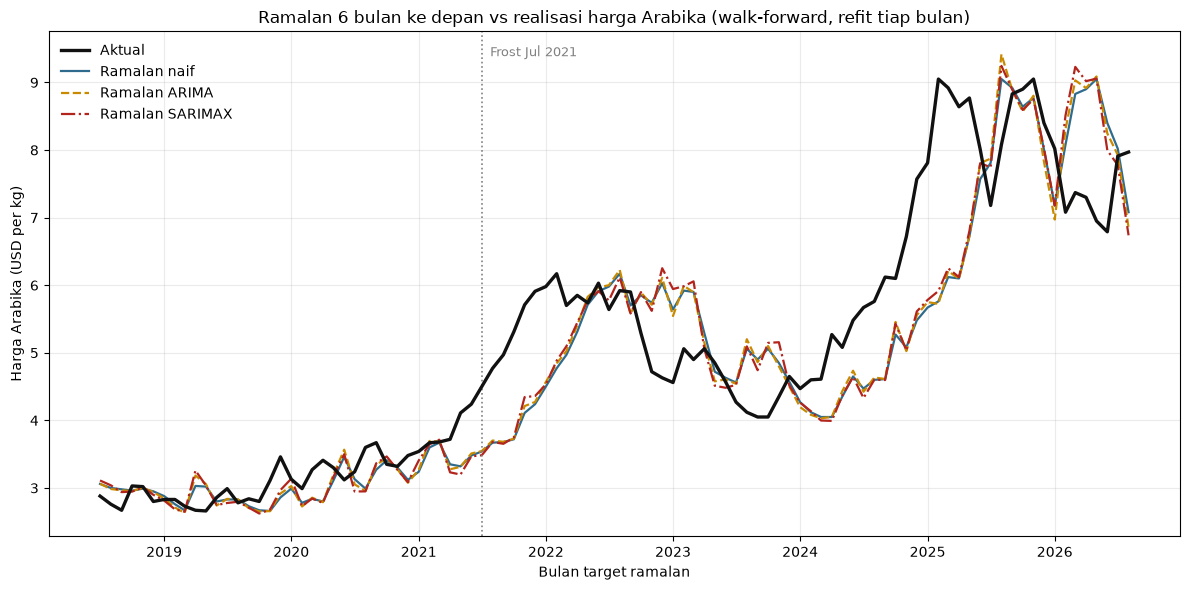

In [6]:
h = 6
subset = predictions[predictions.horizon == h]
wide = subset.pivot(index="target_date", columns="model", values="pred")
actual = subset.drop_duplicates("target_date").set_index("target_date").actual

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(actual.index, actual.values, color="#111", lw=2.4, label="Aktual", zorder=5)
styles = {"naif": ("#2F6B8C", "-"), "ARIMA": ("#C98A00", "--"), "SARIMAX": ("#B3241C", "-.")}
for model, (colour, style) in styles.items():
    ax.plot(wide.index, wide[model], color=colour, ls=style, lw=1.6, label=f"Ramalan {model}")

ax.axvline(pd.Timestamp("2021-07-01"), color="grey", ls=":", lw=1.2)
ax.annotate("Frost Jul 2021", xy=(pd.Timestamp("2021-07-01"), ax.get_ylim()[1]),
            xytext=(6, -10), textcoords="offset points", fontsize=9, color="grey", va="top")

ax.set_title("Ramalan 6 bulan ke depan vs realisasi harga Arabika (walk-forward, refit tiap bulan)")
ax.set_xlabel("Bulan target ramalan")
ax.set_ylabel("Harga Arabika (USD per kg)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "forecast_comparison.png", dpi=150)
plt.show()

## 5. Interpretasi

**Apakah ada model yang mengalahkan naif? Di horizon mana?**

**Tidak ada, di horizon mana pun.** Secara angka mentah hanya satu sel yang rasionya di
bawah 1: SARIMAX pada h=1 dengan MAE 0,2495 vs naif 0,2539 (rasio **0,983**, unggul 1,7%).
Selebihnya kalah: ARIMA 1,003 / 1,016 / 1,014 dan SARIMAX 1,010 / 1,014 pada h=3 dan h=6.

Keunggulan 1,7% itu **tidak berarti secara statistik**. Uji berpasangan pada bulan-bulan yang
sama: rata-rata keunggulan **+0,004 USD/kg** (kurang dari setengah sen per kilogram),
**t = 0,44, p = 0,66**, dan SARIMAX hanya lebih akurat di **53% bulan** — praktis lemparan
koin. Pada h=6, keunggulannya bahkan negatif (−0,010 USD/kg, menang di 44% bulan).

Jadi **prediksi yang ditulis di muka terbukti benar**, termasuk bagian yang paling bisa
menggugurkannya: SARIMAX **tidak** menang di h=6, sehingga tidak ada kontradiksi yang perlu
dijelaskan.

**Kaitannya dengan event study:**

Notebook 04 menunjukkan pasar menyerap kabar frost dalam **lima hari bursa** (+25,5%), lalu
mengoreksi sebagian besarnya pada hari kedelapan. Data bulanan hanya punya satu observasi
per bulan — seluruh drama itu terjadi **di dalam satu titik data**. Pada saat harga bulanan
Juli 2021 tercatat, informasi frost sudah lama dihargai.

Itulah sebabnya cuaca ter-lag tidak menambah daya ramal: variabel seperti `frost_days_total`
lag 6 memberi tahu model sesuatu yang **sudah ada di dalam harga hari ini**. Naif —
"harga besok = harga hari ini" — sudah memuat seluruh informasi itu secara gratis.

Ini bukan kegagalan model, melainkan **bukti tambahan untuk efisiensi pasar** (sub-pertanyaan
3). Dua metode independen menunjuk hal yang sama: harga kopi menyerap kabar cuaca dengan
cepat, dan setelah terserap, tidak ada sisa yang bisa dieksploitasi pada frekuensi bulanan.

**Yang tidak boleh disimpulkan:** ini **bukan** bukti bahwa cuaca tidak memengaruhi harga.
Notebook 02 dan 04 menunjukkan pengaruhnya nyata. Yang ditunjukkan di sini adalah pengaruh
itu **tidak bisa diramalkan** dari data cuaca bulanan yang sudah lewat — dua hal yang
berbeda dan sering tertukar.

## 6. Batasan

- **MAE tumbuh cepat terhadap horizon** (0,25 → 0,52 → 0,72 USD/kg), artinya pada h=6
  ramalan meleset ~13% dari harga. Tak satu pun model di sini berguna untuk keputusan
  bisnis jangka menengah.
- **103 origin, satu pasar.** Kesimpulan "naif tidak terkalahkan" berlaku untuk Arabika
  bulanan 2018–2026, bukan untuk komoditas lain atau frekuensi lain.
- **Order ARIMA dipilih lewat AIC, bukan lewat akurasi out-of-sample.** Itu disengaja
  (memilih lewat akurasi uji akan membocorkan data uji), tapi berarti order-nya belum tentu
  optimal untuk meramal.
- **Horizon panjang memakai regresor lebih sedikit** (5 dari 7 di h=6) akibat aturan
  anti-kebocoran. Sebagian kekalahan SARIMAX di h=6 bisa jadi karena ini — tapi memberinya
  regresor yang belum diketahui akan membuat hasilnya palsu.